# End-to-end demo

The whole recommendation pipeline, **step by step, for one user** — exactly what the Streamlit app does, with the intermediate values made visible and a few of them **recomputed by hand** to show how each number is obtained.

1. Questionnaire answers
2. From answers to a user profile
3. Semantic encoding (SBERT) and cosine similarity
4. The three signals, z-scores and final percentile
5. Category affinity and coverage
6. Final score, Top 3 and explanations
7. Visualizations

In [1]:
# Make the project root importable (notebooks live in notebooks/)
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

## Imports and engine

The engine is the same object as in the app (`Scorer`): category centroids and the semantic profile of every book are precomputed once.

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

from src.data.data import load_config, load_books
from src.data.categories import load_categories
from src import questionnaire as Q
from src.nlp.scoring import Scorer, clean_avoid_text, coverage_weights
from src.nlp.similarity import cosine, percentile_rank
from src.recommendation.engine import recommend
from src.recommendation.explain import CRITERIA_LABELS

config = load_config(ROOT / "configs/data.yaml")
df, vectors = load_books(root=ROOT)
CATEGORIES = list(load_categories(ROOT / "configs/categories.yaml")["categories"])
scorer = Scorer(df, vectors["book"], CATEGORIES, config["embeddings"]["model"])   # summary + genres
print(f"{len(df):,} books | model {config['embeddings']['model']} | book vectors {vectors['book'].shape}")

12,040 books | model all-mpnet-base-v2 | book vectors (12040, 768)


## 1. Questionnaire answers

By default, a complete example (a reader of dystopian science fiction). Set `USE_LATEST_RESPONSE = True` to use instead the last questionnaire submitted in the app (saved as JSON in `data/responses/`).

In [3]:
USE_LATEST_RESPONSE = False

def book_id(title: str) -> int:
    """wikipedia_id of a book from its exact title (for the example)."""
    return int(df.loc[df["title"] == title, "wikipedia_id"].iloc[0])

EXAMPLE = {
    # open-ended questions
    "ideal_book": "A thought-provoking story about a society where technology controls people's lives, "
                  "and one person who starts to question everything",
    "loved_book": "I loved Brave New World for its critique of a society obsessed with comfort and control",
    "avoid": "no romance",
    # Likert 1-5
    "likert": {c: 3 for c in CATEGORIES} | {"Science Fiction": 5, "Literary Fiction": 4, "Romance": 1},
    "importance": dict(Q.IMPORTANCE_DEFAULTS),
    # guided questions
    "atmosphere": "Dark and tense", "pace": "No preference", "complexity": "Moderately complex",
    "settings": ["The future"], "romance": "Doesn't matter", "violence": "Doesn't matter", "supernatural": "No",
    # multiple choice / checkboxes
    "audience": "Adult books", "authors": ["George Orwell"],
    "liked_books": [book_id("Brave New World")], "read_books": [book_id("Nineteen Eighty-Four")],
}

responses = sorted((ROOT / config["paths"]["responses_folder"]).glob("*.json"))
if USE_LATEST_RESPONSE and responses:
    answers = Q.load_answers(responses[-1])
    print("Loaded:", responses[-1].name)
else:
    answers = EXAMPLE
print(json.dumps(answers, indent=1)[:1500])

{
 "ideal_book": "A thought-provoking story about a society where technology controls people's lives, and one person who starts to question everything",
 "loved_book": "I loved Brave New World for its critique of a society obsessed with comfort and control",
 "avoid": "no romance",
 "likert": {
  "Science Fiction": 5,
  "Fantasy": 3,
  "Mystery & Crime": 3,
  "Thriller & Suspense": 3,
  "Horror & Gothic": 3,
  "Romance": 1,
  "Historical": 3,
  "Adventure": 3,
  "Humour & Satire": 3,
  "Literary Fiction": 4,
  "Non-fiction": 3
 },
 "importance": {
  "text": 5,
  "categories": 3,
  "references": 2
 },
 "atmosphere": "Dark and tense",
 "pace": "No preference",
 "complexity": "Moderately complex",
 "settings": [
  "The future"
 ],
 "romance": "Doesn't matter",
 "violence": "Doesn't matter",
 "supernatural": "No",
 "audience": "Adult books",
 "authors": [
  "George Orwell"
 ],
 "liked_books": [
  36681
 ],
 "read_books": [
  23454753
 ]
}


## 2. From answers to a user profile

- The **guided answers** are turned into a sentence, so that they are analysed semantically like the free texts.
- The **"avoid"** text is cleaned of negation words: embeddings capture topics, not negation (*"no romance"* ≈ *"romance"*).
- The Likert ratings and the importance of each criterion are kept as numbers; books loved or read are excluded from the results.

In [4]:
profile = Q.answers_to_profile(answers)

print("Texts analysed (weight, origin):")
for t, w, l in zip(profile.texts, profile.text_weights, profile.text_labels):
    print(f"  [{w}] {l}: {t}")
print("\nAvoid (raw)    :", profile.avoid)
print("Avoid (cleaned):", clean_avoid_text(profile.avoid))
print("Audience:", profile.audience, "| authors:", profile.authors, "| loved:", profile.liked_books,
      "| excluded:", profile.exclude_ids)
print("Importance -> weights:", {k: round(v / sum(profile.importance.values()), 2) for k, v in profile.importance.items()})

Texts analysed (weight, origin):
  [1.0] your description: A thought-provoking story about a society where technology controls people's lives, and one person who starts to question everything
  [1.0] what you said about a book you loved: I loved Brave New World for its critique of a society obsessed with comfort and control
  [0.5] your answers to the guided questions: I am looking for a book with a dark, tense and gripping atmosphere; a plot with some twists; set in the future.

Avoid (raw)    : no romance, magic, supernatural creatures
Avoid (cleaned): romance, magic, supernatural creatures
Audience: adult | authors: ['George Orwell'] | loved: [36681] | excluded: {23454753}
Importance -> weights: {'text': 0.5, 'categories': 0.3, 'references': 0.2}


## 3. Semantic encoding and cosine similarity

Each text becomes a vector of meaning. Books were encoded the same way in advance: the summary (split into sentence chunks, chunk vectors averaged) and the genre list, fused into one vector per book (notebook 02). All vectors are normalized to length 1.

In [5]:
T = scorer.encode(profile.texts)
print("Shape:", T.shape, "| norms:", np.linalg.norm(T, axis=1).round(4))
print("First values of the first vector:", T[0][:8].round(3))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Shape: (3, 768) | norms: [1. 1. 1.]
First values of the first vector: [-0.008  0.061 -0.013 -0.018 -0.033 -0.012  0.058 -0.032]


**Cosine similarity, by hand.** $\cos(u, b) = \dfrac{u \cdot b}{\lVert u \rVert \, \lVert b \rVert}$ — with normalized vectors it is a plain dot product, which is what the engine computes for the 12,000 books at once.

In [6]:
u = T[0]
sims = cosine(u, scorer.emb)[0]
j = int(np.argmax(sims))
by_hand = np.dot(u, scorer.emb[j]) / (np.linalg.norm(u) * np.linalg.norm(scorer.emb[j]))
print(f"Closest book to the first text: {df.at[j, 'title']} ({df.at[j, 'author']})")
print(f"cosine by hand = {by_hand:.6f} | engine = {sims[j]:.6f}")

Closest book to the first text: And Chaos Died (Joanna Russ)
cosine by hand = 0.466308 | engine = 0.466308


**Meaning, not keywords.** For the books closest to the first text, how many words do they share with it (summary only; the genre list is short)? High similarity with few shared words is what distinguishes semantic analysis from keyword matching.

In [7]:
from nltk.corpus import stopwords
STOP = set(stopwords.words("english"))
words = lambda t: {w.strip(".,;:!?\"'()").lower() for w in t.split()} - STOP - {""}

query_words = words(profile.texts[0])
top = np.argsort(-sims)[:8]
pd.DataFrame([{"title": df.at[i, "title"], "cosine": round(float(sims[i]), 3),
               "shared words": len(query_words & words(df.at[i, "synopsis_raw"])),
               "examples": ", ".join(sorted(query_words & words(df.at[i, "synopsis_raw"]))[:6])} for i in top])

,title,cosine,shared words,examples
0,And Chaos Died,0.466,0,
1,Bend Sinister,0.457,2,"society, story"
2,What Technology Wants,0.451,3,"one, question, technology"
3,Limes inferior,0.439,4,"everything, one, starts, story"
4,The Pedestrian,0.435,2,"one, story"
5,My Name is Legion,0.434,0,
6,Daybreak Zero,0.430,2,"question, society"
7,The Fortunate Fall,0.427,2,"one, person"


## 4. The three signals, z-scores and final percentile

Raw similarities have different ranges, so each signal $x_k$ is **standardized** over the corpus ($z_k$ = how many standard deviations above the average book). The weighted mean of the z-scores is the `combined` value; the score is its **percentile** over the corpus (minus the penalty). The percentiles of each signal (`s_`) are only used for the explanations (*"top 1% of the books"*).

In [8]:
result = scorer.score(profile)
cols = ["title", "author", "cos_text", "z_text", "coverage", "z_categories", "cos_references", "z_references",
        "combined", "penalty", "score"]
result.ranking[[c for c in cols if c in result.ranking]].head(10).round(3)

,title,author,cos_text,z_text,coverage,z_categories,cos_references,z_references,combined,penalty,score
2373,Limes inferior,Janusz Zajdel,0.425,3.626,0.816,1.319,0.768,1.280,2.465,0.0,1.000
8699,The Fortunate Fall,Raphael Carter,0.420,3.518,0.854,1.480,0.762,1.201,2.443,0.0,1.000
4048,This Other Eden,Ben Elton,0.415,3.411,0.786,1.195,0.800,1.721,2.408,0.0,1.000
8319,Random Acts of Senseless Violence,Jack Womack,0.402,3.121,0.798,1.244,0.823,2.040,2.341,0.0,1.000
2419,Absolute Friends,John le Carré,0.397,3.020,0.858,1.497,0.812,1.887,2.337,0.0,1.000
3538,Evening's Empire,David Herter,0.389,2.844,0.980,2.006,0.777,1.407,2.305,0.0,1.000
2927,The Jagged Orbit,John Brunner,0.386,2.762,0.922,1.765,0.815,1.932,2.297,0.0,0.999
1698,Earthworks,Brian Aldiss,0.400,3.089,0.889,1.624,0.771,1.318,2.295,0.0,0.999
1166,The Wanting Seed,Anthony Burgess,0.386,2.774,0.823,1.351,0.848,2.401,2.273,0.0,0.999
3230,Alongside Night,J. Neil Schulman,0.417,3.457,0.715,0.897,0.772,1.341,2.266,0.0,0.999


**Checks by hand** on the first book: its text z-score, its combined value, then its final score.

In [9]:
i = result.ranking.index[0]
row = result.ranking.loc[i]
# Weighted mean cosine of the user's texts with EVERY book of the corpus (z-scores are computed over the corpus)
cos_all_books = (np.array(profile.text_weights) @ cosine(T, scorer.emb)) / sum(profile.text_weights)

z_by_hand = (row["cos_text"] - cos_all_books.mean()) / cos_all_books.std()
print(f"Text z-score    : by hand {z_by_hand:.4f} | engine {row['z_text']:.4f}")

combined_by_hand = sum(w * row[f"z_{k}"] for k, w in result.weights.items())
print(f"Combined value  : by hand {combined_by_hand:.4f} | engine {row['combined']:.4f}")
print("  = " + " + ".join(f"{w:.2f} x {row[f'z_{k}']:.2f} ({k})" for k, w in result.weights.items()))

# Percentile over the WHOLE corpus (the ranking hides the filtered books): recompute the 3 signals for every book
z = lambda x: (x - x.mean()) / x.std()
w_hat = coverage_weights(result.category_affinity["affinity"].to_numpy())
coverage_all = scorer.cat_profile @ w_hat / w_hat.sum()
ref = np.mean([v for _, v in result.references], axis=0)
references_all = cosine(ref / np.linalg.norm(ref), scorer.emb)[0]
signals_all = {"text": cos_all_books, "categories": coverage_all, "references": references_all}
combined_all = sum(w * z(signals_all[k]) for k, w in result.weights.items())
p_by_hand = (combined_all < row["combined"]).sum() / (len(combined_all) - 1)
print(f"Final score     : by hand {p_by_hand - row['penalty']:.4f} | engine {row['score']:.4f}  (percentile - penalty {row['penalty']:.3f})")

Text z-score    : by hand 3.6260 | engine 3.6260
Combined value  : by hand 2.4645 | engine 2.4645
  = 0.50 x 3.63 (text) + 0.30 x 1.32 (categories) + 0.20 x 1.28 (references)
Final score     : by hand 1.0000 | engine 1.0000  (percentile - penalty 0.000)


## 5. Category affinity and coverage

$a_c = 0.5 \cdot \text{Likert}_c + 0.5 \cdot \text{semantic}_c$; only the categories above the user's average count in the coverage: $\hat w_c = \max(0, a_c - \bar a)$.

In [10]:
aff = result.category_affinity.copy()
aff["ŵ (coverage weight)"] = coverage_weights(aff["affinity"].to_numpy())
aff.round(3).sort_values("affinity", ascending=False)

,likert,semantic,affinity,ŵ (coverage weight)
category,,,,
Science Fiction,1.00,0.001,0.501,0.239
Literary Fiction,0.75,0.002,0.376,0.114
Thriller & Suspense,0.50,0.002,0.251,0.000
Adventure,0.50,0.002,0.251,0.000
Historical,0.50,0.001,0.251,0.000
Mystery & Crime,0.50,0.001,0.250,0.000
Fantasy,0.50,0.000,0.250,0.000
Humour & Satire,0.50,0.001,0.250,0.000
Horror & Gothic,0.50,0.001,0.250,0.000


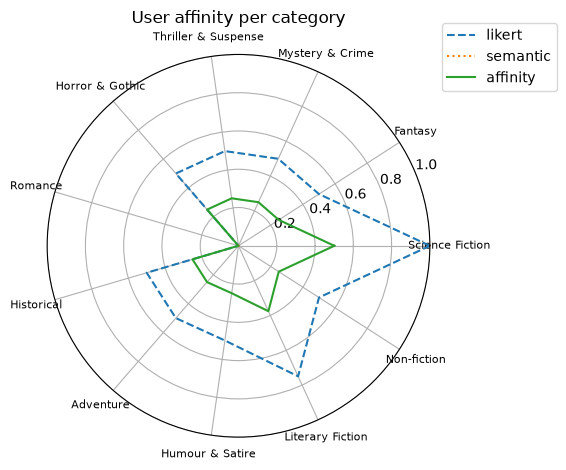

In [11]:
def radar(ax, values, label, **kw):
    """Closed polygon on a polar axis, one axis per category."""
    angles = np.linspace(0, 2 * np.pi, len(CATEGORIES), endpoint=False).tolist()
    ax.plot(angles + angles[:1], list(values) + [values[0]], label=label, **kw)
    ax.set_xticks(angles); ax.set_xticklabels(CATEGORIES, fontsize=8); ax.set_ylim(0, 1)

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw={"polar": True})
for col, style in [("likert", "--"), ("semantic", ":"), ("affinity", "-")]:
    radar(ax, aff[col].fillna(0).to_numpy(), col, linestyle=style)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1)); ax.set_title("User affinity per category")
plt.tight_layout()

## 6. Top 3 and explanations

Explanations are generated from the numbers above with fixed templates (no generative AI). Only the opening of each summary is shown: Wikipedia summaries reveal the ending.

In [12]:
recs = recommend(scorer, result, top_k=10)
for r in recs[:3]:
    print("=" * 100)
    print(f"#{r['rank']}  {r['title']} — {r['author']}  [{', '.join(r['categories'])}]   score {r['score_100']:.2f}/100")
    print("Contributions (weighted z):", {CRITERIA_LABELS[k]: round(v, 2) for k, v in r["contributions"].items()})
    for sentence in r["explanation"]:
        print("  -", sentence.replace("**", "").replace("*", ""))
    print("Opening:", r["opening"])

#1  Limes inferior — Janusz Zajdel  [Science Fiction]   score 100.00/100
Contributions (weighted z): {'Story & themes you described': 1.81, 'Kind of book (categories)': 0.4, 'Closeness to books / authors you love': 0.26}
  - Its story is extremely close to what you asked for (top 0.1% of the books), especially your answers to the guided questions: “I am looking for a book with a dark, tense and gripping atmosphere; a plot with some twists;…”.
  - It is listed as Science Fiction, a kind of book you rated 5/5 (it is in the top 11% of the books closest to this category).
  - It is close to the books of George Orwell, which you love (top 10% of the books).
Opening:  The hero, Adi Cherryson, also known as Sneer (named after one of Zajdel's fellow science fiction writers Adam Wiśniewski-Snerg), is a lifter who "helps" people cheat during the computer controlled IQ exams by giving them the correct answers through a micro-radio communicator or taking the exam for them. Sneer, who is officially

## 7. Visualizations

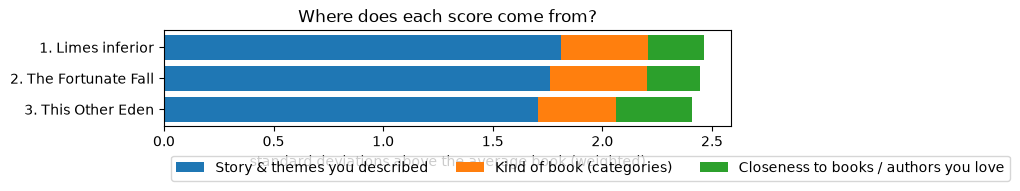

In [13]:
top3 = recs[:3]
fig, ax = plt.subplots(figsize=(9, 2.8))
names = [f"{r['rank']}. {r['title']}" for r in top3][::-1]
left = np.zeros(3)
for k in result.weights:
    vals = np.array([r["contributions"][k] for r in top3][::-1])
    ax.barh(names, vals, left=left, label=CRITERIA_LABELS[k]); left += vals
ax.set_xlabel("standard deviations above the average book (weighted)")
ax.legend(loc="lower left", bbox_to_anchor=(0, -0.65), ncol=3)
ax.set_title("Where does each score come from?"); plt.tight_layout()

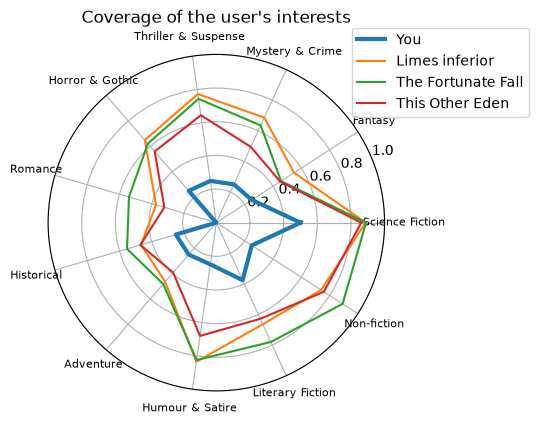

In [14]:
fig, ax = plt.subplots(figsize=(6, 6), subplot_kw={"polar": True})
radar(ax, aff["affinity"].fillna(0).to_numpy(), "You", linewidth=3)
for r in top3:
    radar(ax, scorer.cat_profile[r["row"]], r["title"])
ax.legend(loc="upper right", bbox_to_anchor=(1.45, 1.1)); ax.set_title("Coverage of the user's interests")
plt.tight_layout()

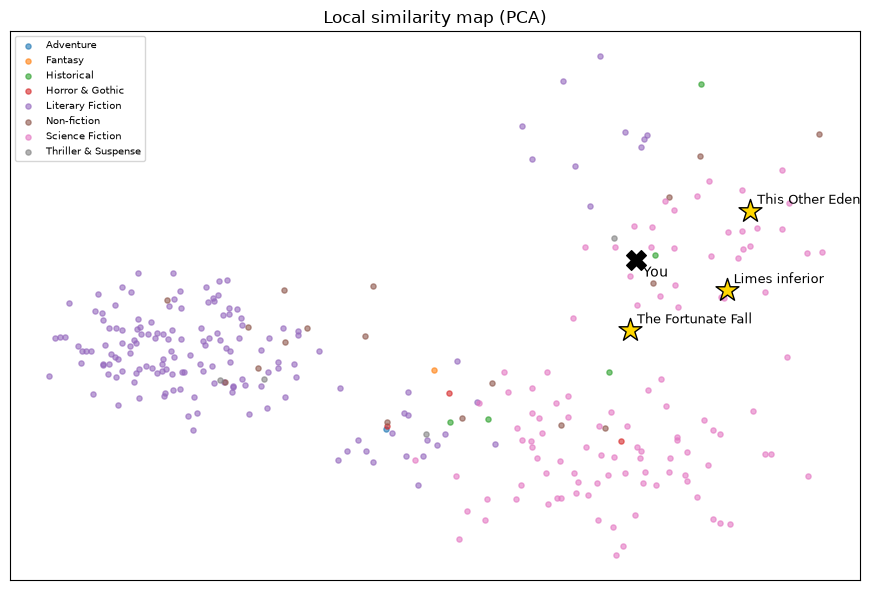

In [15]:
# Similarity map: the 300 books closest to the user, projected in 2D with a PCA of their vectors
neighbours = result.ranking.head(300).index.to_numpy()
pca = PCA(n_components=2, random_state=0).fit(scorer.emb[neighbours])
xy, user_xy = pca.transform(scorer.emb[neighbours]), pca.transform(result.user_vec[None, :])[0]
main_cat = np.array(CATEGORIES)[scorer.cat_raw[neighbours].argmax(1)]

fig, ax = plt.subplots(figsize=(9, 6))
for c in sorted(set(main_cat)):
    m = main_cat == c
    ax.scatter(xy[m, 0], xy[m, 1], s=14, alpha=0.6, label=c)
for r in top3:
    p = xy[np.where(neighbours == r["row"])[0][0]]
    ax.scatter(*p, marker="*", s=300, c="gold", edgecolors="black", zorder=3)
    ax.annotate(r["title"], p, xytext=(5, 5), textcoords="offset points", fontsize=9)
ax.scatter(*user_xy, marker="X", s=200, c="black", zorder=3); ax.annotate("You", user_xy, xytext=(5, -12), textcoords="offset points")
ax.set_xticks([]); ax.set_yticks([]); ax.legend(fontsize=7, loc="best"); ax.set_title("Local similarity map (PCA)")
plt.tight_layout()

The questionnaire answers are stored by the app as one JSON file per submission (`data/responses/`), with the derived texts (guided sentence, avoid text) so that every analysis can be traced and replayed in this notebook.